# Отчёт о качестве данных — ЛР5, вариант 4 (quotes.toscrape.com, обход по тегам)

Источники: `data/crawl.db` (таблицы `quotes`, `authors`, представление `quotes_full`) и `data/stats_*.json` (статистика Scrapy каждого прогона).
Ноутбук можно перезапустить после нового прогона — все цифры пересчитаются.

In [1]:
import glob, json, os, sqlite3
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "quality" else os.getcwd()
DATA = os.path.join(ROOT, "data")
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)

con = sqlite3.connect(os.path.join(DATA, "crawl.db"))
quotes = pd.read_sql("SELECT * FROM quotes", con)
authors = pd.read_sql("SELECT * FROM authors", con)
full = pd.read_sql("SELECT * FROM quotes_full", con)

runs = []
for f in glob.glob(os.path.join(DATA, "stats_*.json")):
    s = json.load(open(f, encoding="utf-8"))
    runs.append(s)
runs.sort(key=lambda s: s["run_number"])
print(f"quotes: {len(quotes)} строк, authors: {len(authors)} строк, quotes_full: {len(full)} строк")
print(f"прогонов в data/: {len(runs)}")

quotes: 232 строк, authors: 49 строк, quotes_full: 232 строк
прогонов в data/: 5


## 1. Все прогоны

In [2]:
def kind(s):
    snap = s.get("settings_snapshot", {})
    if snap.get("JOBDIR"):
        return "JOBDIR"
    if snap.get("HTTPCACHE_ENABLED"):
        return "HTTPCACHE"
    return "основной"

tbl = pd.DataFrame([{
    "прогон": s["run_number"],
    "тип": kind(s),
    "причина": s.get("close_reason"),
    "записей": s.get("item_scraped_count", 0),
    "запросов": s.get("downloader/request_count", 0),
    "dupefilter/filtered": s.get("dupefilter/filtered", 0),
    "cache store": s.get("httpcache/store", 0),
    "cache hit": s.get("httpcache/hit", 0),
    "время, с": s.get("elapsed_s"),
} for s in runs])
print(tbl.to_string(index=False))

 прогон       тип  причина  записей  запросов  dupefilter/filtered  cache store  cache hit  время, с
      1  основной finished      281       202                  378            0          0     247.6
      2    JOBDIR shutdown       71        67                  121            0          0      79.7
      3    JOBDIR finished      210       137                  298            0          0     164.6
      4 HTTPCACHE finished      281       202                  378          202          0     244.0
      5 HTTPCACHE finished      281       202                  378            0        202       2.4


## 2. Полнота полей (итоговая запись = цитата тега + данные автора)

In [3]:
def filled(series):
    return series.fillna("").astype(str).str.strip().ne("").mean() * 100

completeness = pd.DataFrame({
    "поле": full.columns,
    "заполнено, %": [round(filled(full[c]), 1) for c in full.columns],
})
print(completeness.to_string(index=False))
print()
print("цитат без тегов (поле tags пустое по данным сайта):", int((full["tags"].fillna("") == "").sum()))

             поле  заполнено, %
     business_key         100.0
            quote         100.0
           author         100.0
             tags         100.0
       source_tag         100.0
         tag_page         100.0
 author_born_date         100.0
author_born_place         100.0
       author_bio         100.0
       author_url         100.0

цитат без тегов (поле tags пустое по данным сайта): 0


## 3. Основной прогон: пайплайн, отбраковка, коды ответов, повторы, трафик, длительность

In [4]:
main = [s for s in runs if kind(s) == "основной"][-1]
print("основной прогон №", main["run_number"], "| причина остановки:", main["close_reason"])
print("CLOSESPIDER_ITEMCOUNT =", main["settings_snapshot"]["CLOSESPIDER_ITEMCOUNT"])
print()
rows = [(k, v) for k, v in sorted(main.items())
        if k.startswith(("validate/", "clean/", "dropped/", "pipeline/", "errback/", "retry/", "pages/", "tags/"))]
print(pd.DataFrame(rows, columns=["счётчик", "значение"]).to_string(index=False))
dropped = sum(v for k, v in main.items() if k.startswith("dropped/") and k.count("/") == 1)
print()
print("отброшено записей всего:", dropped)

основной прогон № 1 | причина остановки: finished
CLOSESPIDER_ITEMCOUNT = 400

                       счётчик  значение
                 clean/authors        49
            clean/dates_to_iso        49
                  clean/quotes       232
                  pages/author        49
                    pages/list        10
                     pages/tag       142
       pipeline/sqlite_batches         6
       pipeline/sqlite_written       281
pipeline/sqlite_written/author        49
 pipeline/sqlite_written/quote       232
           tags/found_via_list       232
          tags/found_via_top10       100
        validate/passed/author        49
         validate/passed/quote       232

отброшено записей всего: 0


In [5]:
codes = {k.rsplit("/", 1)[1]: v for k, v in main.items() if k.startswith("downloader/response_status_count/")}
total = sum(codes.values())
print(pd.DataFrame([(c, n, f"{n / total:.1%}") for c, n in sorted(codes.items())],
                   columns=["код", "ответов", "доля"]).to_string(index=False))
print()
el = main["elapsed_s"]
print(f"запросов: {main['downloader/request_count']}, повторов (retry/count): {main.get('retry/count', 0)}")
print(f"трафик: получено {main['downloader/response_bytes'] / 1024 / 1024:.2f} МБ, отправлено {main['downloader/request_bytes'] / 1024:.0f} КБ")
print(f"длительность: {el:.0f} с ({int(el // 60)} мин {int(el % 60)} с)")
print(f"скорость: {main['item_scraped_count'] / el * 60:.0f} записей/мин, {main['downloader/request_count'] / el:.2f} запросов/с")
print(f"глубина: request_depth_max = {main.get('request_depth_max')} при DEPTH_LIMIT = {main['settings_snapshot']['DEPTH_LIMIT']}")

код  ответов  доля
200      201 99.5%
404        1  0.5%

запросов: 202, повторов (retry/count): 0
трафик: получено 0.89 МБ, отправлено 62 КБ
длительность: 248 с (4 мин 7 с)
скорость: 68 записей/мин, 0.82 запросов/с
глубина: request_depth_max = 11 при DEPTH_LIMIT = 15


## 4. Агрегаты

In [6]:
top_tags = (full.groupby("source_tag").size().sort_values(ascending=False).head(10)
            .rename("цитат").reset_index())
print("Топ-10 тегов по числу цитат:")
print(top_tags.to_string(index=False))

top_authors = (quotes.drop_duplicates(["author", "quote"]).groupby("author").size()
               .sort_values(ascending=False).head(10).rename("уникальных цитат").reset_index())
print()
print("Топ-10 авторов по числу уникальных цитат:")
print(top_authors.to_string(index=False))

Топ-10 тегов по числу цитат:
          source_tag  цитат
                love     14
       inspirational     13
                life     13
               humor     12
               books     11
             reading      7
          friendship      5
             friends      4
               truth      4
attributed-no-source      3

Топ-10 авторов по числу уникальных цитат:
          author  уникальных цитат
 Albert Einstein                10
    J.K. Rowling                 8
       Dr. Seuss                 6
  Marilyn Monroe                 6
      Mark Twain                 6
     Jane Austen                 5
      C.S. Lewis                 5
      Bob Marley                 3
Charles Bukowski                 2
 Suzanne Collins                 2


In [7]:
authors["век рождения"] = pd.to_datetime(authors["author_born_date"]).dt.year.map(lambda y: f"{(y - 1) // 100 + 1} в.")
by_century = authors.groupby("век рождения").size().rename("авторов")
by_century = by_century.reindex(sorted(by_century.index, key=lambda s: int(s.split()[0])))
print(by_century.to_string())

tags_per_quote = quotes.drop_duplicates(["author", "quote"])["tags"].fillna("").map(lambda t: len([x for x in t.split(",") if x]))
print()
print(f"уникальных цитат: {quotes.drop_duplicates(['author', 'quote']).shape[0]}, тегов: {quotes['source_tag'].nunique()}, авторов: {authors.shape[0]}")
print(f"тегов на цитату: среднее {tags_per_quote.mean():.2f}, медиана {tags_per_quote.median():.0f}, максимум {tags_per_quote.max()}")

век рождения
18 в.     1
19 в.    20
20 в.    28

уникальных цитат: 97, тегов: 137, авторов: 49
тегов на цитату: среднее 2.39, медиана 2, максимум 8


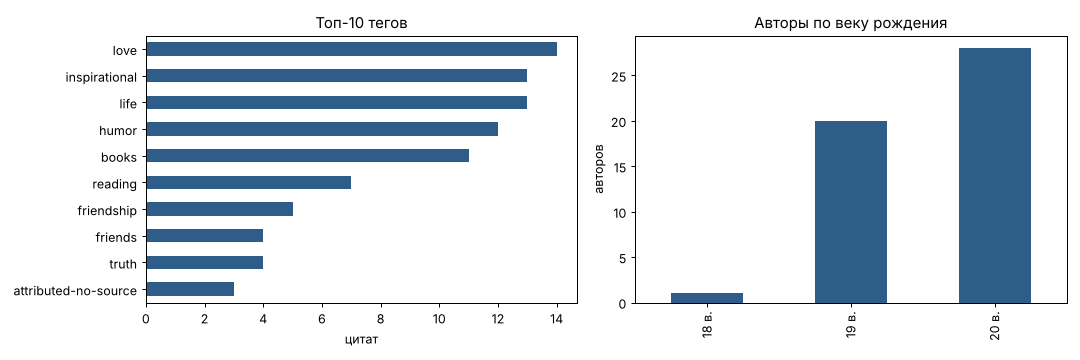

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top_tags.plot.barh(x="source_tag", y="цитат", ax=axes[0], legend=False, color="#2F5D8A")
axes[0].invert_yaxis(); axes[0].set_title("Топ-10 тегов"); axes[0].set_xlabel("цитат"); axes[0].set_ylabel("")
by_century.plot.bar(ax=axes[1], color="#2F5D8A")
axes[1].set_title("Авторы по веку рождения"); axes[1].set_xlabel(""); axes[1].set_ylabel("авторов")
plt.tight_layout()
plt.show()

## 5. Предел источника

На сайте 100 цитат, 137 тегов, 50 авторов; у 3 цитат нет ни одного тега, поэтому при обходе по тегам они (и один автор, у которого других цитат нет) недостижимы.

In [9]:
pairs_site = 232  # сумма длин списков тегов по всем цитатам сайта
print(f"собрано пар «цитата × тег»: {len(quotes)} из {pairs_site} возможных ({len(quotes) / pairs_site:.0%})")
print(f"собрано записей всего (цитаты тегов + авторы): {len(quotes) + len(authors)}")

собрано пар «цитата × тег»: 232 из 232 возможных (100%)
собрано записей всего (цитаты тегов + авторы): 281
